# Skill scores and reference forecasts

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/13-verification.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/13-verification.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `45d7dacdeec041e06c3e61b98278724982236654f93f45257468080bf2caeaf8`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Skill scores and reference forecasts

**Lesson 13 · Original synthetic data · Independent educational project**

## Objectives

Compute bias and RMSE; compare against a declared baseline.

[Previous](12-ensembles.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/13-verification.ipynb) · [Next](14-maps.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=13-verification.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

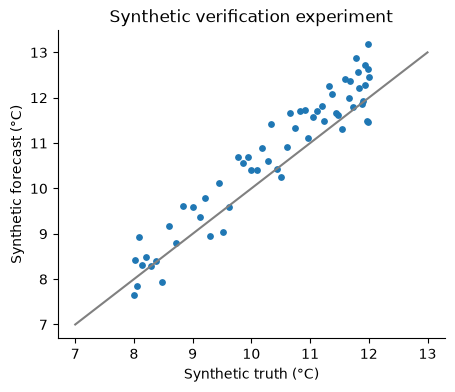

{'bias': np.float64(0.37062489854505093), 'rmse': np.float64(0.575672148230121), 'reference_rmse': np.float64(1.326004854588047), 'skill': np.float64(0.5658596978447967)}


In [2]:
rng = np.random.default_rng(11)
truth = 10 + 2*np.sin(np.arange(60)/6)
forecast = truth + .4 + rng.normal(0, .5, 60)
baseline = np.full(60, truth.mean())
bias = (forecast-truth).mean()
rmse = np.sqrt(np.mean((forecast-truth)**2))
reference_rmse = np.sqrt(np.mean((baseline-truth)**2))
skill = 1-rmse/reference_rmse
assert rmse >= abs(bias)
assert 0 < skill < 1
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(truth, forecast, s=15)
ax.plot([7, 13], [7, 13], color="gray")
ax.set(xlabel="Synthetic truth (°C)", ylabel="Synthetic forecast (°C)", title="Synthetic verification experiment")
plt.show()
print(dict(bias=bias, rmse=rmse, reference_rmse=reference_rmse, skill=skill))

## Exercise

Add a constant 2 °C bias and recompute skill. Then subtract the estimated bias and assess the remaining error.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

A score depends on the reference, sample and event definition. Synthetic truth provides a controlled experiment; this is not an assessment of an operational twin.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://destine.ecmwf.int/weather-induced-extremes-digital-twin/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).